# ЛР3. Градиентный спуск
**Вариант 15 (нечётный) → L2-регуляризация.**

**Цель:** понять, как модель обучается: написать с нуля градиентный спуск для линейной регрессии, исследовать скорость обучения, сравнить GD и SGD, добавить L2-регуляризацию.

**План (по шагам):**
1. Сгенерировать и стандартизовать данные.
2. Написать градиентный спуск и запустить его: смотрим веса и предсказания **до** и **после**.
3. Исследовать скорость обучения `lr`.
4. Стохастический спуск (SGD) и сравнение с GD.
5. L2-регуляризация: 20 значений коэффициента от 0.001 до 1000.

*Запуск: Run All (ячейки выполняются строго сверху вниз, первая ячейка с функциями обязательна). Результаты воспроизводимы (`SEED = 15`).*

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

%matplotlib inline

FIG = os.path.join(os.getcwd(), "figures")
os.makedirs(FIG, exist_ok=True)
SEED = 15
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
np.set_printoptions(precision=4, suppress=True)


def show_objects(X, y, w, title, k=5):
    """Печатает первые k объектов: значения x, настоящий y и предсказание модели с весами w."""
    print(title)
    for i in range(k):
        x = ", ".join(f"{v:7.3f}" for v in X[i, 1:])
        print(f"  объект {i}:  x = [{x}]   y = {y[i]:7.3f}   предсказание = {X[i] @ w:7.3f}")


def show_weights(w, title):
    names = ["w0", "w1", "w2", "w3", "w4"]
    print(title + "  " + "   ".join(f"{n} = {v:7.4f}" for n, v in zip(names, w)))

## Шаг 1. Данные
`make_regression` создаёт 500 объектов с 4 признаками (информативны только 3, один — «пустой») и шумом. Признаки и ответ **стандартизуем** (среднее 0, std 1), чтобы градиентный спуск вёл себя одинаково по всем весам. Добавляем столбец единиц — это свободный член `w0`. Итого **5 весов**.

In [2]:
def make_data():
    """4 признака (3 информативных + 1 бесполезный), шум, затем стандартизация X и y."""
    X, y = make_regression(n_samples=500, n_features=4, n_informative=3, noise=20.0, bias=5.0, random_state=SEED)
    X = StandardScaler().fit_transform(X)                      # каждый признак: среднее 0, std 1
    y = StandardScaler().fit_transform(y.reshape(-1, 1)).ravel()
    X = np.hstack([np.ones((X.shape[0], 1)), X])               # столбец единиц = свободный член w0
    return X, y


def mse(X, y, w):
    """Среднеквадратичная ошибка Q(w) = 1/n * sum (x_i w - y_i)^2."""
    r = X @ w - y
    return float(r @ r / len(y))


In [3]:
X, y = make_data()
n, d = X.shape
print(f"Объектов: {n}, признаков: {d - 1} (+ свободный член), весов: {d}\n")

w_start = np.zeros(d)                       # начальные веса: модель пока ничего не знает
show_weights(w_start, "Начальные веса:")
print()
show_objects(X, y, w_start, "Первые 5 объектов: значения x1..x4, правильный y и предсказание с начальными весами:")

Объектов: 500, признаков: 4 (+ свободный член), весов: 5

Начальные веса:  w0 =  0.0000   w1 =  0.0000   w2 =  0.0000   w3 =  0.0000   w4 =  0.0000

Первые 5 объектов: значения x1..x4, правильный y и предсказание с начальными весами:
  объект 0:  x = [ -0.689,   1.647,   0.795,   0.526]   y =   1.112   предсказание =   0.000
  объект 1:  x = [  1.316,  -1.863,   0.431,  -1.165]   y =  -0.008   предсказание =   0.000
  объект 2:  x = [  0.845,   0.886,  -0.634,   1.039]   y =  -0.134   предсказание =   0.000
  объект 3:  x = [ -0.793,   1.328,  -0.492,   1.608]   y =   0.285   предсказание =   0.000
  объект 4:  x = [  0.028,   0.361,   0.377,  -1.741]   y =  -0.026   предсказание =   0.000


## Шаг 2. Градиентный спуск
Линейная модель: `ŷ = X·w`. Ошибка — MSE: `Q(w) = 1/n · Σ (xᵢw − yᵢ)²`. Градиент `∇Q = 2/n · Xᵀ(Xw − y)` показывает, куда ошибка растёт быстрее всего, поэтому идём **против** него:

$$w^{k} = w^{k-1} - \eta \cdot \nabla Q(w^{k-1}), \qquad \text{стоп, если } \|w^{k}-w^{k-1}\| < \varepsilon$$

**Алгоритм:** старт `w = 0` → цикл: посчитать градиент → сделать шаг `w − lr·grad` → если веса почти не изменились, выйти. Одна функция умеет и обычный GD, и стохастический (SGD), и L2-штраф.

In [4]:
def gradient_descent(X, y, lr=0.1, n_iter=1000, eps=1e-6, stochastic=False, l2=0.0, seed=SEED, w0=None):
    """
    Градиентный спуск для линейной регрессии. Алгоритм (как в задании):
      1) инициализируем веса w и точность eps;
      2) цикл по числу итераций;
      3) w_new = w - lr * grad Q(w);
      4) выходим, если ||w_new - w|| < eps.

    stochastic=True : на каждой итерации берём ОДИН случайный объект (SGD), иначе все n (обычный GD).
    l2 > 0          : L2-регуляризация, к функции потерь добавляется l2 * ||w||^2 (свободный член не штрафуем).
    Возвращает: веса и историю MSE (на всех данных) после каждой итерации.
    """
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d) if w0 is None else w0.copy()               # начальные веса
    history = [mse(X, y, w)]
    for _ in range(n_iter):
        if stochastic:
            i = rng.integers(n)                                # случайный объект
            xi, yi = X[i], y[i]
            grad = 2 * xi * (xi @ w - yi)                      # градиент по одному объекту
        else:
            grad = 2 * X.T @ (X @ w - y) / n                   # градиент по всей выборке
        if l2 > 0:
            reg = 2 * l2 * w
            reg[0] = 0.0                                       # w0 не регуляризуем
            grad = grad + reg
        w_new = w - lr * grad
        history.append(mse(X, y, w_new))
        converged = np.linalg.norm(w_new - w) < eps            # критерий остановки
        w = w_new
        if not np.isfinite(history[-1]) or history[-1] > 1e12: # расходимся - останавливаемся
            break
        if converged:
            break
    return w, np.array(history)

In [5]:
# Эталон: точное аналитическое решение (МНК). К нему должен прийти наш спуск.
w_ref = LinearRegression(fit_intercept=False).fit(X, y).coef_

w_start = np.zeros(d)
print("=== ДО обучения ===")
show_weights(w_start, "Начальные веса:")
show_objects(X, y, w_start, "Предсказания с нулевыми весами (модель ничего не знает):")
print(f"MSE = {mse(X, y, w_start):.4f}\n")

w_gd, h_gd = gradient_descent(X, y, lr=0.1, n_iter=3000, eps=1e-8)

print("=== ПОСЛЕ обучения (GD, lr = 0.1) ===")
print(f"Остановились на итерации {len(h_gd) - 1} (вес перестал меняться: шаг < eps)")
show_weights(w_gd, "Найденные веса:     ")
show_weights(w_ref, "Эталон (МНК):      ")
show_objects(X, y, w_gd, "Предсказания обученной модели:")
print(f"MSE = {h_gd[-1]:.5f}   (было {h_gd[0]:.4f})")
print(f"Расстояние до эталона ‖w − w_МНК‖ = {np.linalg.norm(w_gd - w_ref):.1e}")

=== ДО обучения ===
Начальные веса:  w0 =  0.0000   w1 =  0.0000   w2 =  0.0000   w3 =  0.0000   w4 =  0.0000
Предсказания с нулевыми весами (модель ничего не знает):
  объект 0:  x = [ -0.689,   1.647,   0.795,   0.526]   y =   1.112   предсказание =   0.000
  объект 1:  x = [  1.316,  -1.863,   0.431,  -1.165]   y =  -0.008   предсказание =   0.000
  объект 2:  x = [  0.845,   0.886,  -0.634,   1.039]   y =  -0.134   предсказание =   0.000
  объект 3:  x = [ -0.793,   1.328,  -0.492,   1.608]   y =   0.285   предсказание =   0.000
  объект 4:  x = [  0.028,   0.361,   0.377,  -1.741]   y =  -0.026   предсказание =   0.000
MSE = 1.0000

=== ПОСЛЕ обучения (GD, lr = 0.1) ===
Остановились на итерации 88 (вес перестал меняться: шаг < eps)
Найденные веса:       w0 =  0.0000   w1 =  0.0079   w2 =  0.2770   w3 =  0.9397   w4 =  0.2267
Эталон (МНК):        w0 =  0.0000   w1 =  0.0079   w2 =  0.2770   w3 =  0.9397   w4 =  0.2267
Предсказания обученной модели:
  объект 0:  x = [ -0.689,   1.64

**Что видно.** Сначала все веса нулевые, предсказания равны 0, ошибка MSE = 1 (ничего не угадываем). После обучения веса почти точно совпали с эталоном МНК: главный вклад у `w3` (≈ 0.94), далее `w2` (≈ 0.28) и `w4` (≈ 0.23), а `w1` ≈ 0 — это тот самый «пустой» признак. Предсказания стали близки к настоящим `y`, MSE упала с 1 до 0.048; остаток — шум в данных, его убрать нельзя.

## Шаг 3. Скорость обучения (learning rate)
`lr` — длина шага. Слишком **малая** — спуск идёт верно, но очень долго. **Подходящая** — быстро приходим в минимум. Слишком **большая** — шаг перепрыгивает минимум, ошибка не падает, а растёт: спуск **расходится**. Граница известна: `lr < 1/λmax(XᵀX/n)`. Проверим на шести значениях: от 0.001 до чуть выше границы.

Граница устойчивости: lr < 0.865

lr = 0.001  сошёлся за 4185 итераций,  MSE = 0.04761,  w = [0.    0.008 0.277 0.939 0.226]
lr = 0.01   сошёлся за  548 итераций,  MSE = 0.04761,  w = [0.    0.008 0.277 0.94  0.227]
lr = 0.1    сошёлся за   64 итераций,  MSE = 0.04761,  w = [0.    0.008 0.277 0.94  0.227]
lr = 0.5    сошёлся за    9 итераций,  MSE = 0.04761,  w = [0.    0.008 0.277 0.94  0.227]
lr = 0.82   сошёлся за  123 итераций,  MSE = 0.04761,  w = [0.    0.008 0.277 0.94  0.227]
lr = 0.91   РАСХОДИТСЯ: за 150 итераций MSE выросла до 1.1e+12


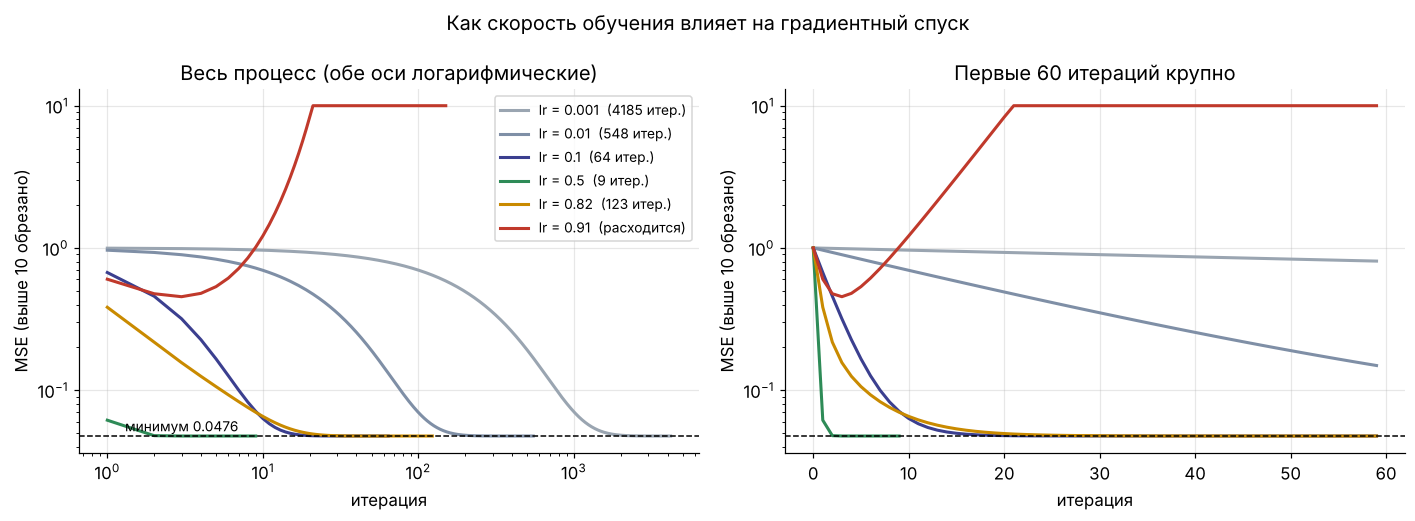

In [6]:
lam = np.linalg.eigvalsh(X.T @ X / n).max()
lr_max = 1 / lam
print(f"Граница устойчивости: lr < {lr_max:.3f}\n")

lrs = [0.001, 0.01, 0.1, 0.5, round(lr_max * 0.95, 2), round(lr_max * 1.05, 2)]
res = {}
for lr in lrs:
    w, h = gradient_descent(X, y, lr=lr, n_iter=5000, eps=1e-6)
    div = (not np.isfinite(h[-1])) or h[-1] > 1e3
    res[lr] = (h, div)
    if div:
        print(f"lr = {lr:<5}  РАСХОДИТСЯ: за {len(h) - 1} итераций MSE выросла до {h[-1]:.1e}")
    else:
        print(f"lr = {lr:<5}  сошёлся за {len(h) - 1:>4} итераций,  MSE = {h[-1]:.5f},  w = {np.round(w, 3)}")

colors = ["#9aa5b1", "#7f8fa6", "#3b3f8f", "#2e8b57", "#c98a00", "#c0392b"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for (lr, (h, div)), col in zip(res.items(), colors):
    hh = np.minimum(h, 10)                                   # расходящуюся кривую обрезаем сверху
    lab = f"lr = {lr}" + ("  (расходится)" if div else f"  ({len(h) - 1} итер.)")
    axes[0].plot(np.arange(1, len(hh)), hh[1:], color=col, lw=2, label=lab)
    axes[1].plot(hh[:60], color=col, lw=2, label=f"lr = {lr}")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("Весь процесс (обе оси логарифмические)")
axes[1].set_yscale("log"); axes[1].set_title("Первые 60 итераций крупно")
for ax in axes:
    ax.set_xlabel("итерация"); ax.set_ylabel("MSE (выше 10 обрезано)")
    ax.axhline(mse(X, y, w_ref), color="k", ls="--", lw=1)
axes[0].text(1.3, mse(X, y, w_ref) * 1.08, "минимум 0.0476", fontsize=9)
axes[0].legend(fontsize=9, loc="upper right")
fig.suptitle("Как скорость обучения влияет на градиентный спуск", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "01_learning_rates.png")); plt.show()

**Что видно на графике.**
- **Каждая линия — один запуск**, по вертикали ошибка MSE (чем ниже, тем лучше), пунктир — минимум, к которому все должны прийти (0.0476).
- Самая пологая линия — `lr = 0.001`: она тянется до **4185** итераций. `lr = 0.01` и `0.1` доходят до дна за 548 и 64 итерации. `lr = 0.5` — почти отвесное падение, всего **9** итераций: это лучший шаг.
- `lr = 0.82` (чуть ниже границы) сходится, но дольше (123): шаг слишком велик и спуск «перепрыгивает» минимум туда-сюда.
- Красная линия `lr = 0.91` (выше границы 0.865) **уходит вверх** и упирается в потолок графика — **расходимость**: ошибка растёт до 10¹², веса уходят в бесконечность.
- На правом графике хорошо видно начало: у `lr = 0.5` ошибка падает до минимума за ~9 шагов, у `lr = 0.001` за те же 60 шагов почти ничего не меняется.

**Вывод:** `lr` влияет на *скорость*, а не на результат (все сошедшиеся запуски пришли к одному минимуму). Выбирать его надо заметно ниже границы устойчивости.

## Шаг 4. Стохастический градиентный спуск (SGD)
GD на каждом шаге читает **все** 500 объектов. SGD берёт **один случайный** объект и считает градиент только по нему: шаг в 500 раз дешевле, но «шумный». Чтобы сравнивать честно, смотрим ошибку не только по итерациям, но и по **числу прочитанных объектов** (итерация GD = 500 объектов, SGD = 1). Для SGD берём `lr = 0.01` и фиксированные 3000 итераций.

Начальные веса:    w0 =  0.0000   w1 =  0.0000   w2 =  0.0000   w3 =  0.0000   w4 =  0.0000
GD,  итоговые:     w0 =  0.0000   w1 =  0.0079   w2 =  0.2770   w3 =  0.9397   w4 =  0.2267
SGD, итоговые:     w0 = -0.0048   w1 = -0.0174   w2 =  0.2782   w3 =  0.9365   w4 =  0.2233
Эталон (МНК):      w0 =  0.0000   w1 =  0.0079   w2 =  0.2770   w3 =  0.9397   w4 =  0.2267

Предсказания SGD:
  объект 0:  x = [ -0.689,   1.647,   0.795,   0.526]   y =   1.112   предсказание =   1.327
  объект 1:  x = [  1.316,  -1.863,   0.431,  -1.165]   y =  -0.008   предсказание =  -0.403
  объект 2:  x = [  0.845,   0.886,  -0.634,   1.039]   y =  -0.134   предсказание =  -0.134
  объект 3:  x = [ -0.793,   1.328,  -0.492,   1.608]   y =   0.285   предсказание =   0.277
  объект 4:  x = [  0.028,   0.361,   0.377,  -1.741]   y =  -0.026   предсказание =   0.060

MSE:  GD = 0.04761,   SGD = 0.04828,   минимум = 0.04761
До MSE <= 0.0500: GD нужно 15 итераций (7500 прочитанных объектов), SGD — 177 итераций (17

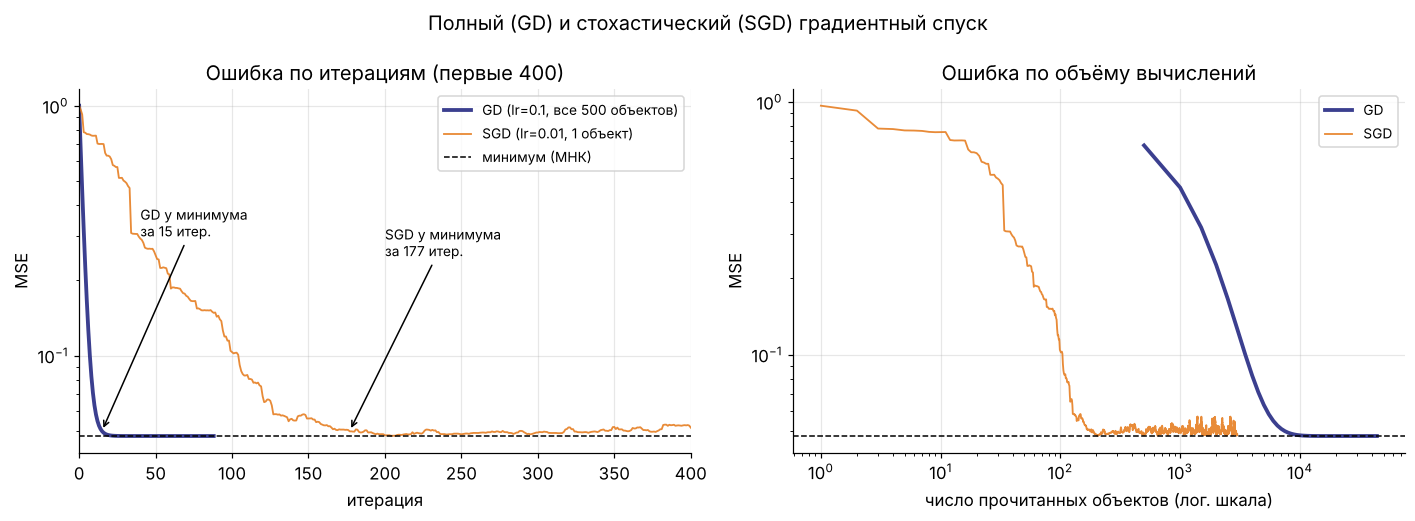

In [7]:
w_sgd, h_sgd = gradient_descent(X, y, lr=0.01, n_iter=3000, eps=0.0, stochastic=True)
base = mse(X, y, w_ref)
thr = base * 1.05                                             # «почти минимум»: в пределах 5%
it_gd = int(np.argmax(h_gd <= thr)); it_sgd = int(np.argmax(h_sgd <= thr))

show_weights(w_start, "Начальные веса:  ")
show_weights(w_gd,    "GD,  итоговые:   ")
show_weights(w_sgd,   "SGD, итоговые:   ")
show_weights(w_ref,   "Эталон (МНК):    ")
print()
show_objects(X, y, w_sgd, "Предсказания SGD:")
print(f"\nMSE:  GD = {h_gd[-1]:.5f},   SGD = {h_sgd[-1]:.5f},   минимум = {base:.5f}")
print(f"До MSE <= {thr:.4f}: GD нужно {it_gd} итераций ({it_gd * n} прочитанных объектов), SGD — {it_sgd} итераций ({it_sgd} объектов)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(h_gd, color="#3b3f8f", lw=2.5, label="GD (lr=0.1, все 500 объектов)")
axes[0].plot(h_sgd, color="#e67e22", lw=1.2, alpha=0.9, label="SGD (lr=0.01, 1 объект)")
axes[0].axhline(base, color="k", ls="--", lw=1, label="минимум (МНК)")
axes[0].set_yscale("log"); axes[0].set_xlim(0, 400)
axes[0].set_xlabel("итерация"); axes[0].set_ylabel("MSE"); axes[0].set_title("Ошибка по итерациям (первые 400)")
axes[0].annotate(f"GD у минимума\nза {it_gd} итер.", xy=(it_gd, thr), xytext=(40, 0.3), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[0].annotate(f"SGD у минимума\nза {it_sgd} итер.", xy=(it_sgd, thr), xytext=(200, 0.25), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[0].legend(fontsize=9)
axes[1].plot(np.arange(1, len(h_gd)) * n, h_gd[1:], color="#3b3f8f", lw=2.5, label="GD")
axes[1].plot(np.arange(1, len(h_sgd)), h_sgd[1:], color="#e67e22", lw=1.2, alpha=0.9, label="SGD")
axes[1].axhline(base, color="k", ls="--", lw=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("число прочитанных объектов (лог. шкала)"); axes[1].set_ylabel("MSE")
axes[1].set_title("Ошибка по объёму вычислений"); axes[1].legend(fontsize=9)
fig.suptitle("Полный (GD) и стохастический (SGD) градиентный спуск", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "02_gd_vs_sgd.png")); plt.show()

**Что видно на графиках.**
- **Слева (по итерациям):** синяя линия GD падает гладко и быстро, уже на 15-й итерации она у минимума. Оранжевая SGD спускается дольше (≈ 177 итераций) и всё время **«дрожит»**, потому что каждый шаг делается по одному объекту.
- **Справа (по числу прочитанных объектов):** картина обратная. GD, чтобы подойти к минимуму, прочитал 15 × 500 = **7500** объектов, SGD — всего **177**. Оранжевая линия дошла до дна намного левее синей.
- **В конце** GD ложится ровно на пунктир (0.04761), а SGD остаётся чуть выше (0.04828) и продолжает колебаться: шум отдельных объектов не исчезает при постоянном `lr`.

**Вывод:** по числу итераций быстрее GD, по объёму вычислений — SGD (поэтому его используют на больших данных). Шум SGD лечат уменьшением `lr` по ходу обучения или мини-батчами.

## Шаг 5. L2-регуляризация (Ridge)
**Зачем.** Без ограничений модель может «подгоняться под шум»: веса становятся огромными, а на новых данных она ошибается (переобучение). Регуляризация добавляет к ошибке **штраф за большие веса**:

$$Q_{L2}(w) = \text{MSE}(w) + \alpha \sum_j w_j^2, \qquad \nabla Q_{L2} = \nabla\text{MSE} + 2\alpha w$$

В спуск она добавляется одной строкой: к градиенту прибавляется `2·α·w` — «пружина», тянущая каждый вес к нулю. Коэффициент `α` — сила штрафа: при `α → 0` это обычная регрессия, при `α → ∞` все веса прижаты к нулю и модель предсказывает просто среднее. **L2** сжимает веса плавно, почти никогда не обнуляя (в отличие от L1). Свободный член `w0` не штрафуется. Чем больше `α`, тем меньше нужно брать `lr` — поэтому `lr = 0.5/(1+α)`.

По заданию берём **20 значений `α` от 0.001 до 1000** (`np.logspace(-3, 3, 20)`).

Расхождение с sklearn.Ridge: 1.0e-11  (практически ноль, реализация верна)

Без регуляризации (МНК):       w0 =  0.0000   w1 =  0.0079   w2 =  0.2770   w3 =  0.9397   w4 =  0.2267
alpha =    0.001  ->  MSE 0.048:  w0 =  0.0000   w1 =  0.0078   w2 =  0.2767   w3 =  0.9387   w4 =  0.2264
alpha =    0.695  ->  MSE 0.219:  w0 =  0.0000   w1 = -0.0173   w2 =  0.1558   w3 =  0.5434   w4 =  0.1164
alpha =    6.158  ->  MSE 0.762:  w0 = -0.0000   w1 = -0.0095   w2 =  0.0348   w3 =  0.1267   w4 =  0.0233
alpha = 1000.000  ->  MSE 0.998:  w0 =  0.0000   w1 = -0.0001   w2 =  0.0002   w3 =  0.0009   w4 =  0.0002

Предсказания при alpha = 0.001:
  объект 0:  x = [ -0.689,   1.647,   0.795,   0.526]   y =   1.112   предсказание =   1.315
  объект 1:  x = [  1.316,  -1.863,   0.431,  -1.165]   y =  -0.008   предсказание =  -0.365
  объект 2:  x = [  0.845,   0.886,  -0.634,   1.039]   y =  -0.134   предсказание =  -0.108

Предсказания при alpha = 6.158:
  объект 0:  x = [ -0.689,   1.647,   0.795,   

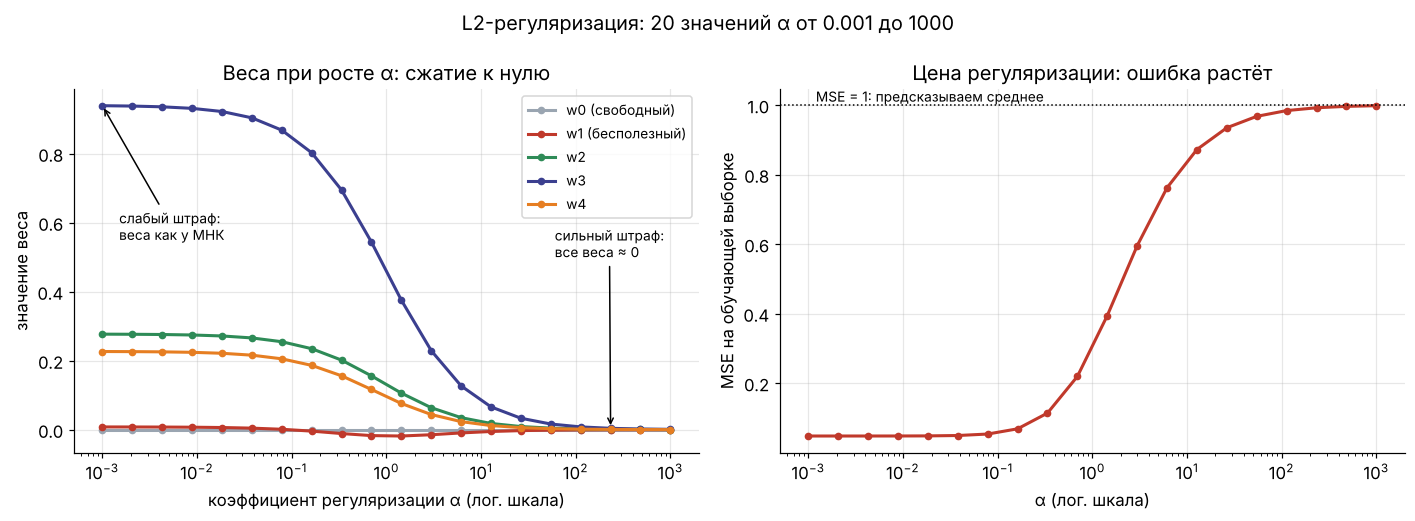

In [8]:
alphas = np.logspace(-3, 3, 20)
W, M = [], []
for a in alphas:
    w, h = gradient_descent(X, y, lr=0.5 / (1 + a), n_iter=40000, eps=1e-10, l2=a)
    W.append(w); M.append(mse(X, y, w))
W = np.array(W); M = np.array(M)

# проверка с sklearn.Ridge (alpha_sklearn = alpha * n)
diff = max(float(np.abs(W[k] - np.r_[r.intercept_, r.coef_]).max())
           for k, a in enumerate(alphas) for r in [Ridge(alpha=a * n).fit(X[:, 1:], y)])
print(f"Расхождение с sklearn.Ridge: {diff:.1e}  (практически ноль, реализация верна)\n")

show_weights(w_ref, "Без регуляризации (МНК):     ")
for k in [0, 9, 12, 19]:
    show_weights(W[k], f"alpha = {alphas[k]:8.3f}  ->  MSE {M[k]:.3f}:")
print()
for k in [0, 12, 19]:
    show_objects(X, y, W[k], f"Предсказания при alpha = {alphas[k]:.3f}:", k=3)
    print()

names = ["w0 (свободный)", "w1 (бесполезный)", "w2", "w3", "w4"]
cols = ["#9aa5b1", "#c0392b", "#2e8b57", "#3b3f8f", "#e67e22"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for j in range(d):
    axes[0].plot(alphas, W[:, j], marker="o", ms=4, lw=2, color=cols[j], label=names[j])
axes[0].set_xscale("log"); axes[0].set_xlabel("коэффициент регуляризации α (лог. шкала)")
axes[0].set_ylabel("значение веса"); axes[0].set_title("Веса при росте α: сжатие к нулю"); axes[0].legend(fontsize=9)
axes[0].annotate("слабый штраф:\nвеса как у МНК", xy=(alphas[0], W[0, 3]), xytext=(0.0015, 0.55), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[0].annotate("сильный штраф:\nвсе веса ≈ 0", xy=(alphas[-3], W[-3, 3]), xytext=(60, 0.5), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[1].plot(alphas, M, marker="o", ms=4, lw=2, color="#c0392b")
axes[1].axhline(1.0, color="k", ls=":", lw=1); axes[1].text(0.0012, 1.01, "MSE = 1: предсказываем среднее", fontsize=9)
axes[1].set_xscale("log"); axes[1].set_xlabel("α (лог. шкала)"); axes[1].set_ylabel("MSE на обучающей выборке")
axes[1].set_title("Цена регуляризации: ошибка растёт")
fig.suptitle("L2-регуляризация: 20 значений α от 0.001 до 1000", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "03_l2_weights.png")); plt.show()

**Что видно на графиках.**
- **Слева — веса.** Каждая линия — один вес при росте `α` (ось X логарифмическая). При малых `α` (слева) веса такие же, как у обычной регрессии: `w3` ≈ 0.94, `w2` ≈ 0.28, `w4` ≈ 0.23. По мере роста `α` **все линии плавно спускаются к нулю**: у главного веса `w3` ≈ 0.23 уже при `α ≈ 3`, а при `α = 1000` все веса практически нулевые. Красная линия — «пустой» признак `w1`: он и так почти ноль и остаётся у нуля (лишь слегка колеблется в пределах шума). Серая линия свободного члена `w0` не штрафуется и лежит на нуле.
- **Справа — ошибка.** С ростом `α` MSE на обучении **растёт**: от 0.048 до 0.6 при `α ≈ 3` и до 0.998 при `α = 1000`. Это значение близко к 1 — ошибке модели «всегда предсказывать среднее» (недообучение).
- В печати выше видно то же самое на конкретных объектах: при `α = 0.001` предсказания почти равны настоящим `y`, при `α = 1000` все предсказания ≈ 0.

**Вывод:** L2 сжимает веса к нулю (но не обнуляет), делает модель устойчивее, но ценой роста ошибки на обучающей выборке. Слишком большое `α` убивает модель, поэтому его подбирают на новых данных.

## Итог
- Градиентный спуск, написанный с нуля, нашёл те же веса, что и точная формула (МНК): `w ≈ [0, 0.008, 0.277, 0.940, 0.227]`, MSE упала с 1 до 0.048.
- Скорость обучения: `lr = 0.001` → 4185 итераций, `lr = 0.5` → 9 итераций, `lr` выше границы 0.865 → расходимость.
- SGD дешевле по вычислениям (177 объектов против 7500), но «шумит» около минимума.
- L2 (вариант 15): веса плавно сжимаются к нулю, ошибка на обучении растёт, при `α = 1000` модель вырождается в константу.